# Quick EDA of the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")

In [2]:
songs_df = pd.read_csv('/kaggle/input/spotify-unpopular-songs/unpopular_songs.csv')
songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,explicit,popularity,track_name,track_artist,track_id
0,0.530,0.7700,4,-6.633,0,0.0389,0.284,0.501000,0.744,0.6230,120.144,225696,False,2,No Regrets,James Reeder,6f2c4a9lNx8aowZJngv7cJ
1,0.565,0.7300,1,-6.063,1,0.0730,0.365,0.000000,0.237,0.5110,130.026,158093,False,2,Wild Life,James Reeder,3fTs52jsDzSuVLsifxNKO8
2,0.427,0.5460,4,-8.727,1,0.0849,0.539,0.015200,0.368,0.4350,78.345,167262,False,2,Fangs,James Reeder,6NPafqavrv0icaIHMQnXDy
3,0.421,0.5310,7,-5.516,1,0.0262,0.706,0.000208,0.110,0.3830,85.080,236832,False,2,Afterburner,James Reeder,3vGmhxveURgmlZStvo0uc1
4,0.537,0.8040,8,-7.378,0,0.1570,0.379,0.000489,0.323,0.5430,139.950,239400,False,2,Hellfire Rising,James Reeder,4O2qRbfCHzMMgfbw9DBdGf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10872,0.686,0.1320,0,-20.363,1,0.0339,0.268,0.001050,0.181,0.4910,95.987,285286,False,7,Bugs n Toes,"Good Girl, Bad Boy",2ykd7eWIVcI3ck7x4OR9T1
10873,0.532,0.0573,11,-20.476,0,0.0479,0.900,0.087700,0.111,0.0731,114.123,360729,False,7,Scattered Thoughts,"Good Girl, Bad Boy",4ceFgUuLwydkHyMK9qnMW8
10874,0.589,0.0308,3,-27.237,1,0.0405,0.943,0.014200,0.106,0.5040,83.952,286585,False,7,Travelin Bug,"Good Girl, Bad Boy",5HASiM0dbIU1saPBEAlVfw
10875,0.669,0.0381,7,-18.631,1,0.0382,0.783,0.000000,0.182,0.1730,99.841,349454,False,7,Goodnight,"Good Girl, Bad Boy",7eqGtA8qyFgozTSBqGrEws


In [3]:
fig = px.box(songs_df, y=["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"], title = 'Distribution of audio features variables')
fig.show()

<AxesSubplot:title={'center':'Distribution of popularity by BPM'}, xlabel='tempo', ylabel='popularity'>

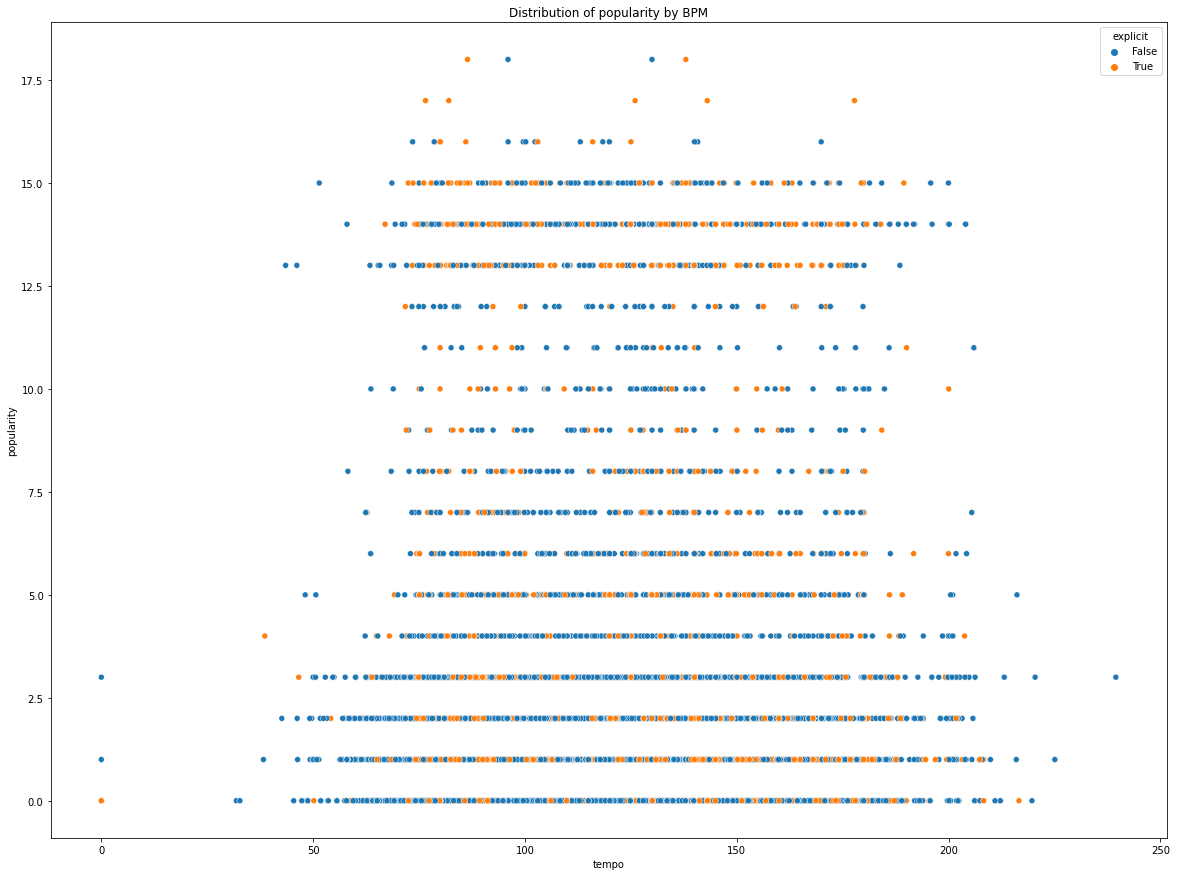

In [4]:
plt.figure(figsize = (20,15))
plt.title('Distribution of popularity by BPM')
sns.scatterplot(data = songs_df, x = 'tempo', y = 'popularity', hue = 'explicit')

# Data pre-processing to analyse its structure

I'm not going to any NLU in this notebook so I'll drop the text columns

In [5]:
songs_df.drop(['track_name','track_artist','track_id'], axis = 1, inplace = True)
songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,explicit,popularity
0,0.530,0.7700,4,-6.633,0,0.0389,0.284,0.501000,0.744,0.6230,120.144,225696,False,2
1,0.565,0.7300,1,-6.063,1,0.0730,0.365,0.000000,0.237,0.5110,130.026,158093,False,2
2,0.427,0.5460,4,-8.727,1,0.0849,0.539,0.015200,0.368,0.4350,78.345,167262,False,2
3,0.421,0.5310,7,-5.516,1,0.0262,0.706,0.000208,0.110,0.3830,85.080,236832,False,2
4,0.537,0.8040,8,-7.378,0,0.1570,0.379,0.000489,0.323,0.5430,139.950,239400,False,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10872,0.686,0.1320,0,-20.363,1,0.0339,0.268,0.001050,0.181,0.4910,95.987,285286,False,7
10873,0.532,0.0573,11,-20.476,0,0.0479,0.900,0.087700,0.111,0.0731,114.123,360729,False,7
10874,0.589,0.0308,3,-27.237,1,0.0405,0.943,0.014200,0.106,0.5040,83.952,286585,False,7
10875,0.669,0.0381,7,-18.631,1,0.0382,0.783,0.000000,0.182,0.1730,99.841,349454,False,7


In [6]:
songs_df['explicit'] = (songs_df['explicit'] == True) * 1 # Categorical to numerical

In [7]:
std_songs_df = (songs_df - songs_df.mean()) / songs_df.std()
std_songs_df

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,explicit,popularity
0,-0.208935,0.855361,-0.337903,0.696155,-1.336128,-0.618819,-0.205808,0.726361,2.794821,0.579979,0.074260,0.188434,-0.607456,-0.269271
1,-0.036946,0.700003,-1.166559,0.780116,0.748362,-0.405810,0.031788,-0.631214,0.130648,0.169948,0.391056,-0.444771,-0.607456,-0.269271
2,-0.715074,-0.014648,-0.337903,0.387706,0.748362,-0.331475,0.542180,-0.590026,0.819024,-0.108287,-1.265726,-0.358890,-0.607456,-0.269271
3,-0.744558,-0.072907,0.490754,0.860690,0.748362,-0.698151,1.032039,-0.630650,-0.536708,-0.298659,-1.049816,0.292740,-0.607456,-0.269271
4,-0.174537,0.987416,0.766972,0.586415,-1.336128,0.118906,0.072854,-0.629889,0.582559,0.287100,0.709198,0.316793,-0.607456,-0.269271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10872,0.557644,-1.622611,-1.442778,-1.326292,0.748362,-0.650052,-0.252741,-0.628369,-0.163619,0.096728,-0.700161,0.746586,-0.607456,0.978540
10873,-0.199107,-1.912743,1.595629,-1.342937,-1.336128,-0.562600,1.601096,-0.393570,-0.531454,-1.433200,-0.118760,1.453225,-0.607456,0.978540
10874,0.080989,-2.015669,-0.614121,-2.338841,0.748362,-0.608825,1.727228,-0.592736,-0.557728,0.144321,-1.085978,0.758753,-0.607456,0.978540
10875,0.474107,-1.987316,0.490754,-1.071166,0.748362,-0.623192,1.257902,-0.631214,-0.158364,-1.067467,-0.576610,1.347618,-0.607456,0.978540


Now the data is ready to be analyzed, let's see what we can get

# Let's look at the constitution of the data (PCA)

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components = len(std_songs_df.columns))
pca.fit(std_songs_df)
pca.explained_variance_ratio_

array([0.23809562, 0.12163969, 0.09601012, 0.08325377, 0.07269563,
       0.06679047, 0.06368654, 0.05909651, 0.05490056, 0.04381433,
       0.03306667, 0.02817767, 0.02491718, 0.01385523])

In [9]:
pca.explained_variance_ratio_[:7].sum()
# 74.2% of the variation in the data can be explained by the 7 first principal components

0.7421718341098107

Let's see what characterizes the first 3 vectors :

In [10]:
pca.components_[:3]

array([[-0.34174953, -0.36703808, -0.01969415, -0.44369801,  0.02892419,
        -0.21085494,  0.36162565,  0.37853647,  0.010247  , -0.33037507,
        -0.16538806, -0.09113151, -0.27047361, -0.11750883],
       [-0.31245016,  0.38308419,  0.00232026,  0.23421816,  0.13082043,
        -0.47175477, -0.18829507,  0.03602349,  0.26286776,  0.00110925,
         0.11164373,  0.34689944, -0.45960396, -0.10582324],
       [-0.31308319,  0.23080248,  0.15028504, -0.07727167, -0.30067196,
         0.3327221 , -0.13013672, -0.01157985,  0.60498494, -0.35200746,
        -0.12331759, -0.04094226,  0.29613155, -0.08649812]])

In [11]:
# I selected here (arbitrarily) the components with absolute value > 0.3
print(std_songs_df.columns[[0,1,3,6,7,9]].values)
print(std_songs_df.columns[[0,1,5,11,12]].values)
print(std_songs_df.columns[[0,4,5,6,7]].values)

['danceability' 'energy' 'loudness' 'acousticness' 'instrumentalness'
 'valence']
['danceability' 'energy' 'speechiness' 'duration_ms' 'explicit']
['danceability' 'mode' 'speechiness' 'acousticness' 'instrumentalness']


Those features are the most important within the vectors that characterize the better the data, thus they are the ones that differentiate the more each data point. We can see that 'danceability', 'energy', 'acousticness', 'speechiness' and 'instrumentalness' appear in more than one of those vectors and thus are really characterizing the data. We can notice that it is also the features that are the most humanly interpretable, we can tell easily if a song is 'danceable' but we would be struggling more (for most of us) if we had to determine the key or the tempo of the song, which is really interesting.

# Let's try to clusterize those songs ! (K-means)

In [12]:
pca_array = pca.transform(std_songs_df)
pca_array.shape

(10877, 14)

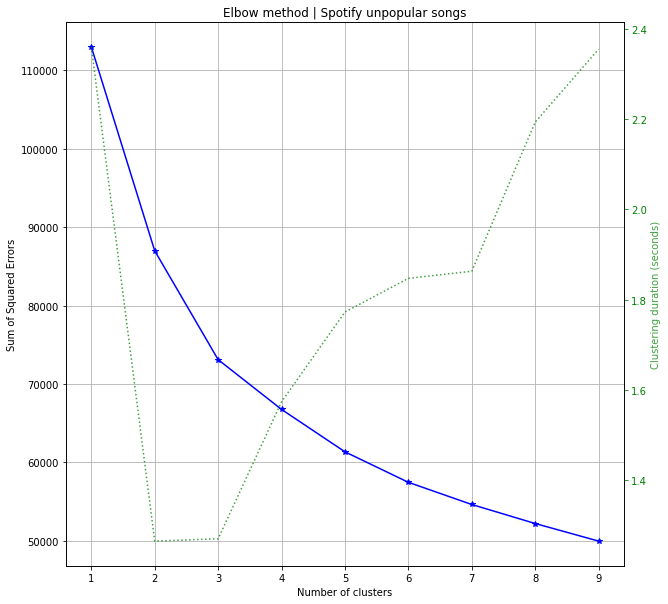

In [13]:
from sklearn.cluster import KMeans
import scikitplot as skplt
import umap

kmeans = KMeans()

skplt.cluster.plot_elbow_curve( kmeans,
                                X = pca_array[:,:7], # Let's use only the first 7 PC
                                title = 'Elbow method | Spotify unpopular songs',
                                cluster_ranges = range(1, 10),
                                show_cluster_time = True,
                                figsize = (10,10))
plt.show()

4 clusters seems to be a good number of clusters.

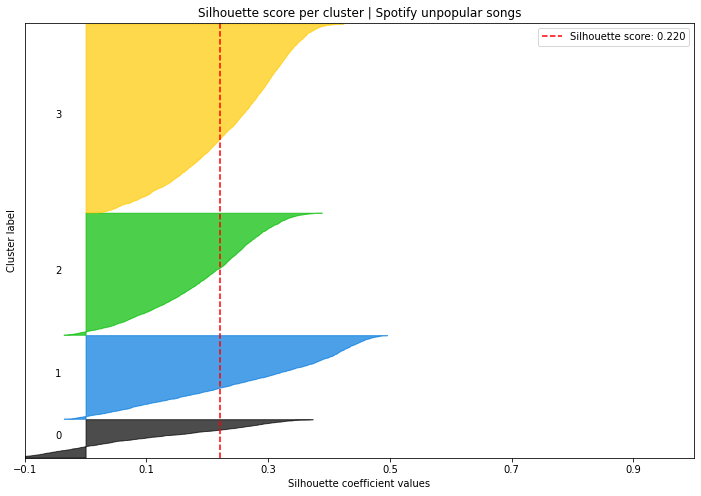

In [14]:
kmeans = KMeans(n_clusters = 4)
kmeans.fit(pca_array[:,:7])

skplt.metrics.plot_silhouette(pca_array[:,:7],
                            kmeans.labels_,
                            title='Silhouette score per cluster | Spotify unpopular songs',
                            figsize=(12,8))
plt.show()

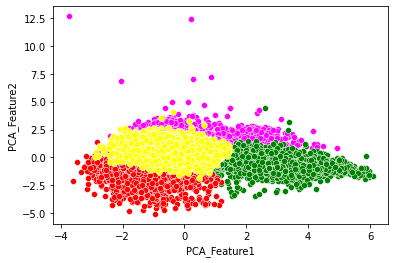

In [15]:
# This cell was added after the notebook of Nikita Sharma : https://www.kaggle.com/code/enesblue/final-songs-clustering-km

pca_distribution = pd.DataFrame(pca_array[:,:2], columns = ['PCA_Feature1','PCA_Feature2'])
pca_distribution["No_of_clusters"] = kmeans.labels_

a = pca_distribution[pca_distribution.No_of_clusters==0]
b = pca_distribution[pca_distribution.No_of_clusters==1]
c = pca_distribution[pca_distribution.No_of_clusters==2]
d = pca_distribution[pca_distribution.No_of_clusters==3]

sns.scatterplot(a["PCA_Feature1"],a["PCA_Feature2"],color="magenta")
sns.scatterplot(b["PCA_Feature1"],b["PCA_Feature2"],color="green")
sns.scatterplot(c["PCA_Feature1"],c["PCA_Feature2"],color="red")
sns.scatterplot(d["PCA_Feature1"],d["PCA_Feature2"],color="yellow")

plt.show()

We can see that the two first principal components characterize a lot our kmeans since it separates the 4 clusters with very little overlapping.

#  Interpretation of clusters with Skope Rules

Let's get back to clustering on the raw data (no PCA applied) to try and understand the clusters created with the features. Skope Rules will print the 'high performing rules' of each cluster.

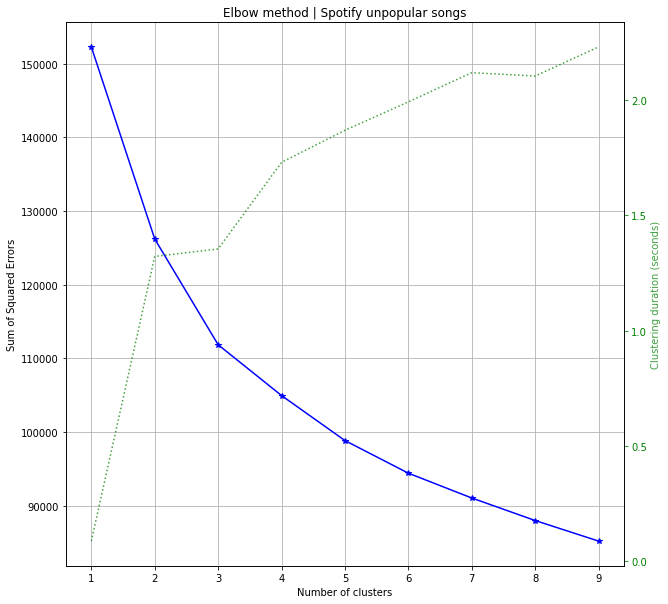

In [16]:
kmeans = KMeans()

skplt.cluster.plot_elbow_curve( kmeans,
                                X = std_songs_df, # Let's use only the first 7 PC
                                title = 'Elbow method | Spotify unpopular songs',
                                cluster_ranges = range(1, 10),
                                show_cluster_time = True,
                                figsize = (10,10))
plt.show()

In [17]:
# Let's take 5 clusters !

kmeans = KMeans(n_clusters = 5)
kmeans.fit(std_songs_df)

KMeans(n_clusters=5)

In [18]:
!pip install skope-rules

In [19]:
import six
import sys
sys.modules['sklearn.externals.six'] = six
from skrules import SkopeRules
from sklearn.model_selection import train_test_split

Cluster 0:
danceability <= 0.9483051300048828 and explicit <= 0.5193005800247192 and liveness > 1.7675116062164307
Precision 0.91


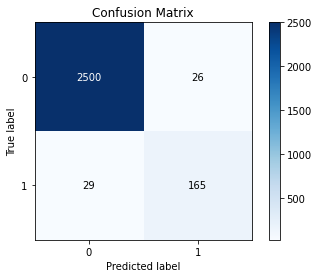

Cluster 1:
popularity > 1.6024449467658997 and acousticness <= 1.4954981207847595 and valence > -1.5735989809036255
Precision 0.98


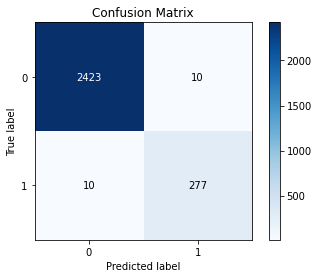

Cluster 2:
danceability > -1.201557457447052 and explicit > 0.5193005800247192 and popularity <= 1.3528828024864197
Precision 0.98


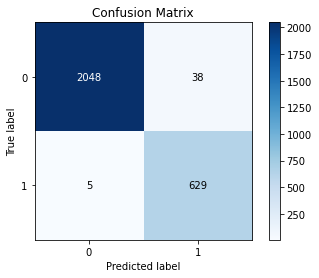

Cluster 3:
explicit <= 0.5193005800247192 and popularity <= 1.3528828024864197 and loudness > -0.43865446746349335
Precision 0.82


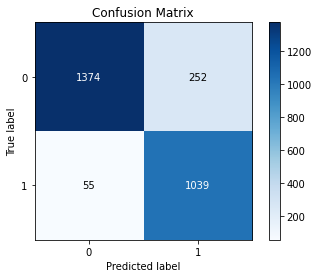

Cluster 4:
energy <= -1.04584139585495 and explicit <= 0.5193005800247192 and acousticness > 0.9543066620826721
Precision 0.95


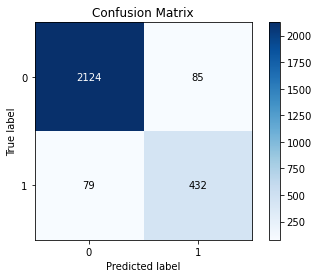

In [20]:
for i_cluster in range(5): # As we said, one classifier for each cluster
    
    X = std_songs_df # The data
    y = (kmeans.labels_ == i_cluster) * 1 # The labels that we're going to use
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify= y)  # We split the data stratified by the cluster and we could even cross validate but not today
    
    skope_rules_clf = SkopeRules(feature_names= std_songs_df.columns, # To get the rule in understable terms we could rename them but not today
                                    random_state=42)

    skope_rules_clf.fit(X_train, y_train) # We fit the rules creator
    
    print('Cluster '+str(i_cluster)+':') # To order results we're printing a "header"
    
    print(skope_rules_clf.rules_[0][0]) # The data structure It's a little messy to just print it so we're accesing the first rule here
    
    print('Precision {:.2f}'.format(skope_rules_clf.rules_[0][1][0])) # And here we're accesing the Precision for the first rule
    
    skplt.metrics.plot_confusion_matrix(y_test, skope_rules_clf.predict(X_test)) # Look who's back! Scikit plot!

    plt.show()


So we have one cluster with **non explicit songs, low energy and studio**; one with **live songs which are not explicit and not really danceable**; one with **non explicit songs with low popularity and which are pretty loud**; one characterized by **the most popular of the unpopular songs**; and finally one with songs that are at least **a bit danceable, explicit but not popular** within the unpopular songs !

Thank you for reading ! Do not hesitate  to comment if you have a question and drop a like if you enjoyed the analysis.

Credits : @tomas-bonfiglio who made a notebook to learn to use some of the libraries used in this notebook. <br>
https://deepnote.com/@tomas-bonfiglio/Enhance-your-clustering-projects-4f5efaa1-5bc4-4195-979e-865992eb0408